In [1]:
import ethnohack.cox_model.cox_model_api as cox

dataset = cox.load_dataset()

/home/jenna/workspace/ethnohack/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = cox.clean_data(dataset, smiles_col="Smiles", label_col="Activity")
data = cox.add_scaffolds(data)

Unparsable SMILES removed: 0
Compounds: 4520 | actives: 2492
(55.1%)


In [3]:
# settings
SPLIT_MODE = "scaffold"  # "scaffold" = honest, "random" = optimistic, "both" = run both and compare
N_TRIALS = 30  # Optuna trials; lower = faster
TIMEOUT_MIN = 15  # hard stop for the search

results = cox.run_models(data, SPLIT_MODE, n_trials=N_TRIALS, timeout_min=TIMEOUT_MIN)
result = results[-1]


SPLIT: SCAFFOLD   FEATURES: ecfp
train: 3610 | test: 910 | scaffold overlap: 0


Best trial: 18. Best value: 0.788418: 100%|██████████| 30/30 [07:23<00:00, 14.78s/it, 443.40/900 seconds]


Best CV PR-AUC: 0.788 | params: {'n_estimators': 600, 'max_depth': 35, 'min_samples_leaf': 1, 'max_features': 'log2', 'criterion': 'entropy', 'class_weight': 'balanced'}

Prevalence (random-guess PR-AUC): 0.552
PR-AUC   : 0.809
ROC-AUC  : 0.774
MCC      : 0.391
Precision: 0.721
Recall   : 0.745
F1       : 0.733


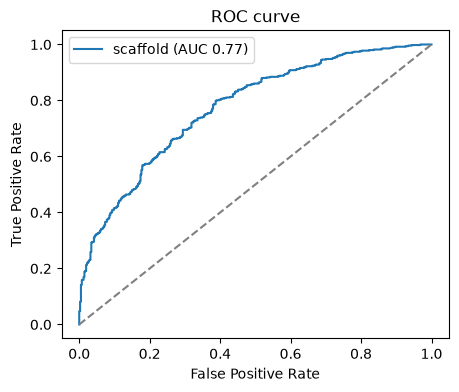

Saved: /home/jenna/workspace/ethnohack/src/ethnohack/cox_model/cox_model.joblib


In [4]:
cox.plot_roc(results)
cox.save_model(result)

Explanation stuff: actually the model is just mildly better than baseline, as the signal mostly stems from the structure itself, it basically performs just as well as basic Similarity Search, but might be computationally more efficient

In [5]:
# nearest-active-neighbour baseline
sim_to_active = cox.similarity_baseline(result)

Similarity baseline ROC-AUC: 0.76
Similarity baseline PR-AUC : 0.792
Your model      ROC-AUC: 0.774
Your model      PR-AUC : 0.809


In [6]:
combo = cox.combined_baseline(result, sim_to_active)

Combined ROC-AUC: 0.785
Combined PR-AUC : 0.82
